# Live/Dead Assay Image Analysis

In [ ]:
#My adjusted code Dec. 30th
# Set the path to your images
#images_path = folder_path
import os
# Step 1: List all images in the folder that do not end with "C"
folder_path = "/Users/allisonpickle/Desktop/Test/0riginal CZI"
image_files = [f for f in os.listdir(folder_path) if f.endswith('.czi')]
#display_size = (800, 600)

# Function to display and interactively adjust brightness
def adjust_brightness(img, channel_num, brightness_factor):
    
    for image_file in image_files:
    # Read the image using czifile
        image_path = os.path.join(folder_path, image_file)
        img = cziread(image_path)

     # Adjust brightness
        adjusted_img = cv2.convertScaleAbs(img, alpha=brightness_factor, beta=0)

     # Resize the adjusted image before displaying
      
 #       resized_img = cv2.resize(adjusted_img, display_size)
   # Select the first channel from the image
    adjusted_img_2d = adjusted_img[0, :, :, 0]

      # Display the adjusted image inline in the notebook
    plt.imshow(adjusted_img_2d, cmap='gray')
    # Display the adjusted image inline in the notebook
   #  plt.imshow(adjusted_img, cmap='gray')
    plt.title(f"Adjusted Image - Channel {channel_num}")
    plt.axis('off')
    plt.show()

    return adjusted_img
folder_path = "/Users/allisonpickle/Desktop/Test/0riginal CZI"
adjust_brightness(folder_path, 2, 2)
#def adjust_brightness(image, channel_num, brightness_factor):

In [292]:
import os
import cv2
import numpy as np
from czifile import imread as cziread
import matplotlib.pyplot as plt
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

### Import the images to analyze

In [293]:
# Step 1: List all images in the folder that do not end with "C"
folder_path = "C:\\Users\\aless\\OneDrive - University of California, Davis\\experiments\\eAA076 - Rat Triculture Experiment with 6 proteins\\data\\Live Dead Assay\\Plate 1"
image_files = [f for f in os.listdir(folder_path) if not f.endswith("C.czi")] # I removed the images from contaminated wells
image_files

['B3 - 1.czi',
 'B3 - 2.czi',
 'B3 - 3.czi',
 'B5 - 1.czi',
 'B5 - 2.czi',
 'B5 - 3.czi',
 'B8 - 1.czi',
 'B8 - 2.czi',
 'B8 - 3.czi',
 'C10 - 1.czi',
 'C10 - 2.czi',
 'C10 - 3.czi',
 'C11 - 1.czi',
 'C11 - 2.czi',
 'C11 - 3.czi',
 'C2 - 1.czi',
 'C2 - 2.czi',
 'C2 - 3.czi',
 'C3 - 1.czi',
 'C3 - 2.czi',
 'C3 - 3.czi',
 'C9 - 1.czi',
 'C9 - 2.czi',
 'C9 - 3.czi',
 'D10 - 1.czi',
 'D10 - 2.czi',
 'D10 - 3.czi',
 'D5 - 1.czi',
 'D5 - 2.czi',
 'D5 - 3.czi',
 'D6 - 1.czi',
 'D6 - 2.czi',
 'D6 - 3.czi',
 'D7 - 1.czi',
 'D7 - 2.czi',
 'D7 - 3.czi',
 'D9 - 1.czi',
 'D9 - 2.czi',
 'D9 - 3.czi',
 'E10 - 1.czi',
 'E10 - 2.czi',
 'E10 - 3.czi',
 'E2 - 1.czi',
 'E2 - 2.czi',
 'E2 - 3.czi',
 'E3 - 1.czi',
 'E3 - 2.czi',
 'E3 - 3.czi',
 'E4 - 1.czi',
 'E4 - 2.czi',
 'E4 - 3.czi',
 'E8 - 1.czi',
 'E8 - 2.czi',
 'E8 - 3.czi',
 'E9 - 1.czi',
 'E9 - 2.czi',
 'E9 - 3.czi',
 'F11 - 1.czi',
 'F11 - 2.czi',
 'F11 - 3.czi',
 'F2 - 1.czi',
 'F2 - 2.czi',
 'F2 - 3.czi',
 'F4 - 1.czi',
 'F4 - 2.czi',
 'F4 - 3.c

#### Determining size and shape of the image files

In [294]:
# Loop through the images
for image_file in image_files:
    # Read the image using czifile
    image_path = os.path.join(folder_path, image_file)
    img = cziread(image_path)

    # Display the shape of the img array
    print(img.shape)
    break 

(2, 1040, 1388, 1)


### Step 1: Adjust Brightness

We perform this step to increase signal to noise ratio in the original image. This will help in further steps, where feature discrimination is important.

##### Defining the function

In [295]:
# Set the path to your images
images_path = folder_path

# Function to display and interactively adjust brightness
def adjust_brightness(image, channel_num, brightness_factor):
    # Adjust brightness
    adjusted_img = cv2.convertScaleAbs(image, alpha=brightness_factor, beta=0)

    # Resize the adjusted image before displaying
    resized_img = cv2.resize(adjusted_img, display_size)

    # Display the adjusted image inline in the notebook
    plt.imshow(resized_img, cmap='gray')
    plt.title(f"Adjusted Image - Channel {channel_num}")
    plt.axis('off')
    plt.show()

    return adjusted_img

##### Apply to the image set
Note: the adjusted images (and all subsequent processed images) are saved in a dictionary, so they are local to this notebook and will not be saved to your computer.

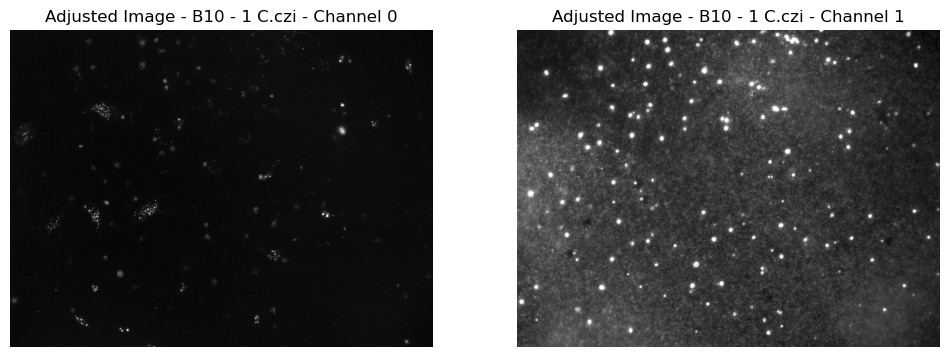

In [296]:
# Initialize a dictionary to store adjusted images
adjusted_images = {}

# Flag to control display for the example image
display_example = True

# Loop through each image in the directory
for filename in os.listdir(images_path):
    if filename.endswith(".czi"):
        # Read the image using czifile
        image_path = os.path.join(images_path, filename)
        img = cziread(image_path)

        # Initialize a list to store adjusted channel images
        adjusted_channels = []

        # Apply processing to each channel
        for channel_num in range(img.shape[0]):
            # Get the channel image
            channel_img = img[channel_num, :, :, 0]

            # Adjust brightness (you need to set the desired brightness_factor)
            brightness_factor = 0.40  # Set your desired brightness factor
            adjusted_img = cv2.convertScaleAbs(channel_img, alpha=brightness_factor, beta=0)

            # Store adjusted image in the list
            adjusted_channels.append(adjusted_img)

        # Convert the list to a numpy array and store it in the dictionary
        adjusted_images[filename] = np.array(adjusted_channels)

        # Display the adjusted images for both channels for the example image
        if display_example:
            example_filename = filename  # Change this to the desired example image filename
            
            # Display both channels side by side
            plt.figure(figsize=(12, 6))
            plt.subplot(1, 2, 1)
            plt.imshow(adjusted_images[example_filename][0], cmap='gray')
            plt.title(f"Adjusted Image - {example_filename} - Channel 0")
            plt.axis('off')

            plt.subplot(1, 2, 2)
            plt.imshow(adjusted_images[example_filename][1], cmap='gray')
            plt.title(f"Adjusted Image - {example_filename} - Channel 1")
            plt.axis('off')
            
            plt.show()
        
        display_example = False  # Disable further display after the example image is displayed

In [297]:
# Verifying that the adjustment was applied to all images
for filename, adjusted_channels in adjusted_images.items():
    print(f"Filename: {filename}")
    for channel_num, adjusted_img in enumerate(adjusted_channels):
        print(f"Channel {channel_num}: Shape {adjusted_img.shape}, Data Type {adjusted_img.dtype}")


Filename: B10 - 1 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B10 - 2 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B10 - 3 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B11 - 1 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B11 - 2 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B11 - 3 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B2 - 1 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B2 - 2 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B2 - 3 C.czi
Channel 0: Shape (1040, 1388), Data

### Step 2: Filtering

This step is performed to further reduce noisy signal and further enhance the features of interest. The idea is to help the subsequent thresholding function to perform better. There are many types of filters; here, I try a few to determine what could work best for this image set.

##### Gaussian Blur
A Gaussian filter is a linear filter that also smooths an image and reduces noise. However, unlike a mean filter – for which even the furthest away pixels in the neighborhood influence the result by the same amount as the closest pixels – the smoothing of a Gaussian filter is weighted so that the influence of a pixel decreases with its distance from the filter center. This tends to give a better result in many cases.

The coefficients of a Gaussian filter are determined from a Gaussian function. The scaling factor A is used to make the entire volume under the surface equal to 1. In terms of filtering, this means that the coefficients add to 1 and the image will not be unexpectedly scaled. The size of the function is controlled by sigma, rather than a filter radius. Sigma is equivalent to the standard deviation of a normal (i.e. Gaussian) distribution.


A small filter will mostly suppress noise, because noise masquerades as tiny random fluctuations at individual pixels. As the filter size increases, Gaussian filtering starts to suppress larger structures occupying multiple pixels – reducing their intensities and increasing their sizes, until eventually they would be smoothed into surrounding regions. By varying the filter size, we can then decide the scale at which the processing and analysis should happen.

In the code below, I use the GaussianBlur function from the OpenCV library. If the sigma value is set to 0 meaning that OpenCV will automatically calculate the SD based on the provided kernel size.

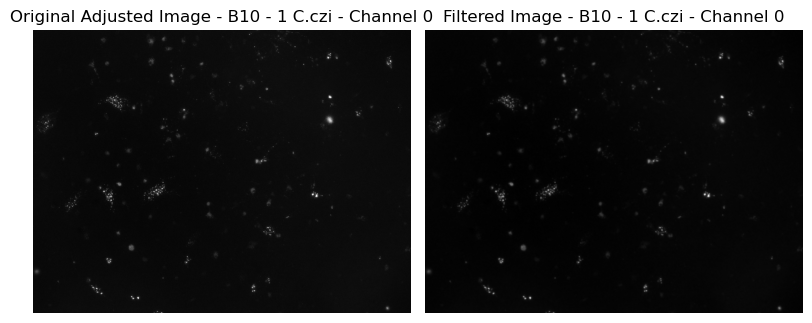

In [298]:
# Initialize dictionaries to store filtered images
filtered_images = {}

# Flag to control display for the example image
display_example = True

# Loop through each adjusted image in the dictionary
for filename, adjusted_channels in adjusted_images.items():
    # Initialize a list to store filtered channel images
    filtered_channels = []

    # Apply processing to each adjusted channel
    for channel_num in range(adjusted_channels.shape[0]):
        # Get the adjusted channel image
        adjusted_img = adjusted_channels[channel_num]

        # Apply filtering (replace this with your filtering code)
        # For example, applying Gaussian Blur
        blurred_img = cv2.GaussianBlur(adjusted_img, (5, 5), 1.5)  # (5,5) is the kernel size and 1.5 is the sigma of that kernel

        # Store filtered image in the list
        filtered_channels.append(blurred_img)

    # Convert the list to a numpy array and store it in the dictionary
    filtered_images[filename] = np.array(filtered_channels)

    # Display the filtered images for the example image
    if display_example:
        example_filename = filename  # Change this to the desired example image filename
        
        plt.figure(figsize=(8, 10))

        # Original adjusted image
        plt.subplot(1, 2, 1)
        plt.imshow(adjusted_images[example_filename][0], cmap='gray')
        plt.title(f"Original Adjusted Image - {example_filename} - Channel 0")
        plt.axis('off')

        # Filtered image
        plt.subplot(1, 2, 2)
        plt.imshow(filtered_images[example_filename][0], cmap='gray')
        plt.title(f"Filtered Image - {example_filename} - Channel 0")
        plt.axis('off')

        # Adjust layout for better visualization
        plt.tight_layout()
        plt.show()

    display_example = False  # Disable further display after the example image is displayed

# Access the filtered images using filtered_images[filename]


In [299]:
# Verifying that the adjustment was applied to all images
for filename, filtered_channels in filtered_images.items():
    print(f"Filename: {filename}")
    for channel_num, filtered_img in enumerate(filtered_channels):
        print(f"Channel {channel_num}: Shape {filtered_img.shape}, Data Type {filtered_img.dtype}")


Filename: B10 - 1 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B10 - 2 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B10 - 3 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B11 - 1 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B11 - 2 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B11 - 3 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B2 - 1 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B2 - 2 C.czi
Channel 0: Shape (1040, 1388), Data Type uint8
Channel 1: Shape (1040, 1388), Data Type uint8
Filename: B2 - 3 C.czi
Channel 0: Shape (1040, 1388), Data

### Quantifying the filter effect
Sometimes, it can be hard to see the effect of the filtering visually. My solution was to attempt to quantify the difference between the images to evaluate the effect of the filter mathematically. Quantifying the difference between two images can be done using various image similarity metrics. One common metric is the Structural Similarity Index (SSI) or Mean Squared Error (MSE). 

This code calculates the SSIM and MSE between the original adjusted image and the filtered image. The closer the SSIM is to 1 and the lower the MSE, the more similar the images are. You can use these values to quantify the difference.

The Mean Squared Error (MSE) is a measure of the average squared difference between corresponding pixels in two images. It is calculated as the average of the squared differences between pixel values. The minimum and maximum values for MSE depend on the range of pixel values in the images.

For an 8-bit grayscale image (common in many cases), the pixel values range from 0 to 255. In this case, the minimum MSE value is 0 (indicating perfect similarity) when the two images are identical. The maximum MSE value occurs when the pixel values in the two images differ maximally for each pixel and can be at most 255^2 (65025).

In [300]:
from skimage.metrics import structural_similarity as ssim
from sklearn.metrics import mean_squared_error

# Example filename
example_filename = next(iter(filtered_images.keys()))

# Original and filtered images
original_img = adjusted_images[example_filename][0]
filtered_img = filtered_images[example_filename][0]

# Calculate SSIM
ssim_value, _ = ssim(original_img, filtered_img, full=True)

# Calculate MSE
mse_value = mean_squared_error(original_img, filtered_img)

print(f"SSIM: {ssim_value:.4f}")
print(f"MSE: {mse_value:.4f}")


SSIM: 0.9397
MSE: 4.4384


##### Difference of Gaussians (DoG) and Laplacian of Gaussians (LoG)

I wanted to see if other filters could improve the results. The main challenge with the Gaussian filter is mainly used to remove small structures. But maybe suppressing large noisy structures, as could be the case in a cell culture dish, could work better. This would allow us to focus on particles within a given size range. 

Here is the idea: suppose we apply one Gaussian filter to reduce small structures. Then we apply a second Gaussian filter, bigger than the first, to a duplicate of the original image. This will remove even more structures, while still preserving the largest features in the image. The trick is that, if we subtract this second filtered image from the first, we are left with an image that contains the information that ‘falls between’ the two smoothing scales we used.

This process is called difference of Gaussians (DoG) filtering. It is especially useful for detecting small structures, or as an alternative to the gradient magnitude for enhancing edges.

One minor complication with DoG filtering is the need to select two different values of sigma. A similar operation, which requires only a single sigma and a single filter, is Laplacian of Gaussian (LoG) filtering. The appearance of a LoG filter is like an upside-down DoG filter, but if the resulting image is inverted then the results are comparable.

I tried both on our image set and compared them.

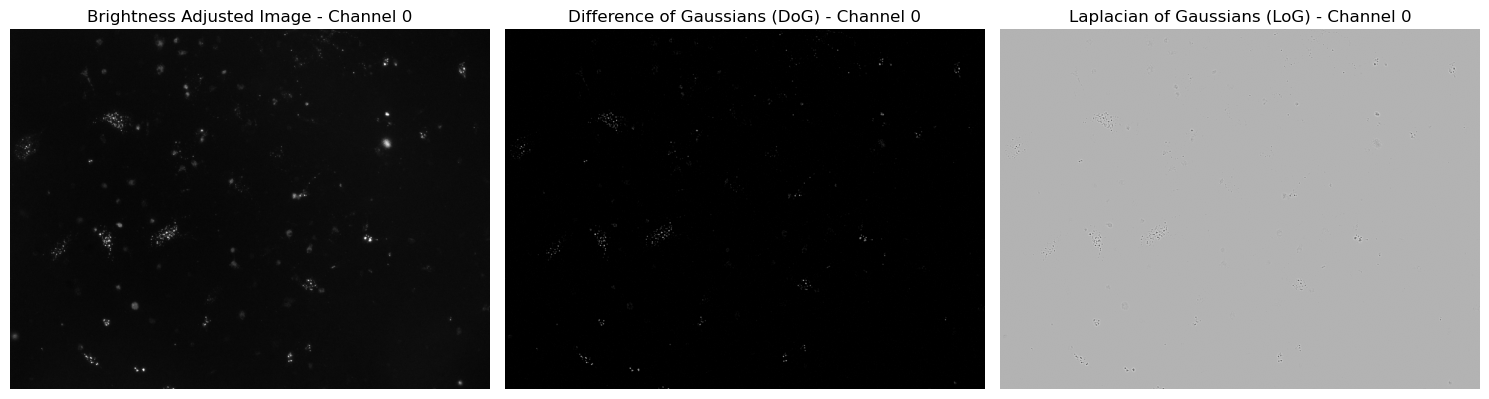

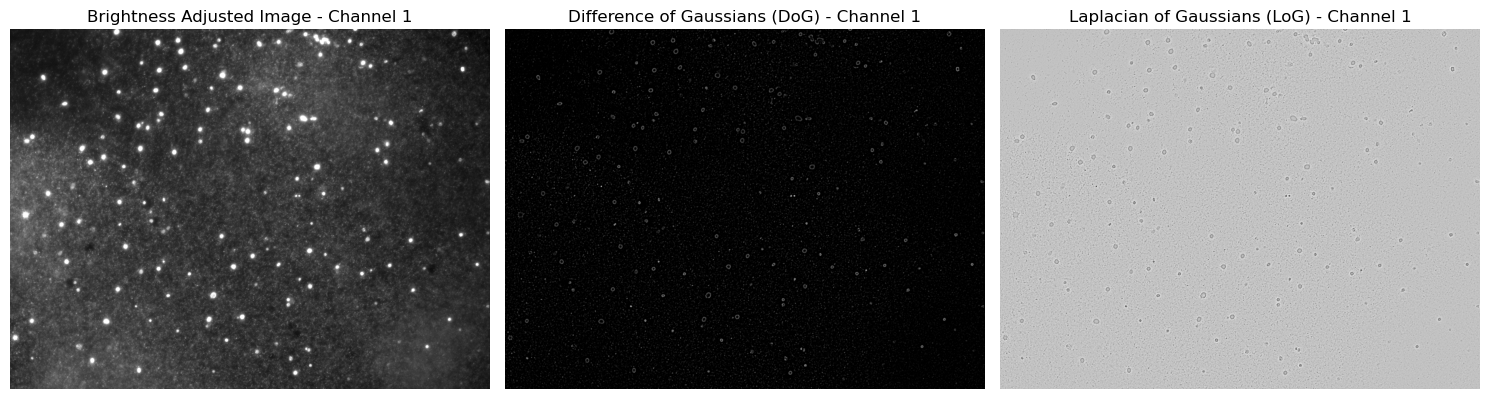

In [301]:
import cv2

# Example filename
example_filename = next(iter(filtered_images.keys()))

# Loop through each channel of the adjusted images
for channel_num in range(adjusted_images[example_filename].shape[0]):
    # Original and filtered images
    adjusted_img = adjusted_images[example_filename][channel_num]

    # Difference of Gaussians (DoG) filter
    dog_filtered_img = cv2.subtract(cv2.GaussianBlur(adjusted_img, (5, 5), 0), cv2.GaussianBlur(adjusted_img, (9, 9), 0))

    # Laplacian of Gaussians (LoG) filter
    log_filtered_img = cv2.Laplacian(cv2.GaussianBlur(adjusted_img, (5, 5), 0), cv2.CV_64F)

    # Increase figure size and adjust spacing
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(adjusted_img, cmap='gray')
    plt.title(f"Brightness Adjusted Image - Channel {channel_num}")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(dog_filtered_img, cmap='gray')
    plt.title(f"Difference of Gaussians (DoG) - Channel {channel_num}")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(log_filtered_img, cmap='gray')
    plt.title(f"Laplacian of Gaussians (LoG) - Channel {channel_num}")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

From these images, the LoG method seemed more promising, as it didn't only retain the edges. I decided to proceed further with that option.

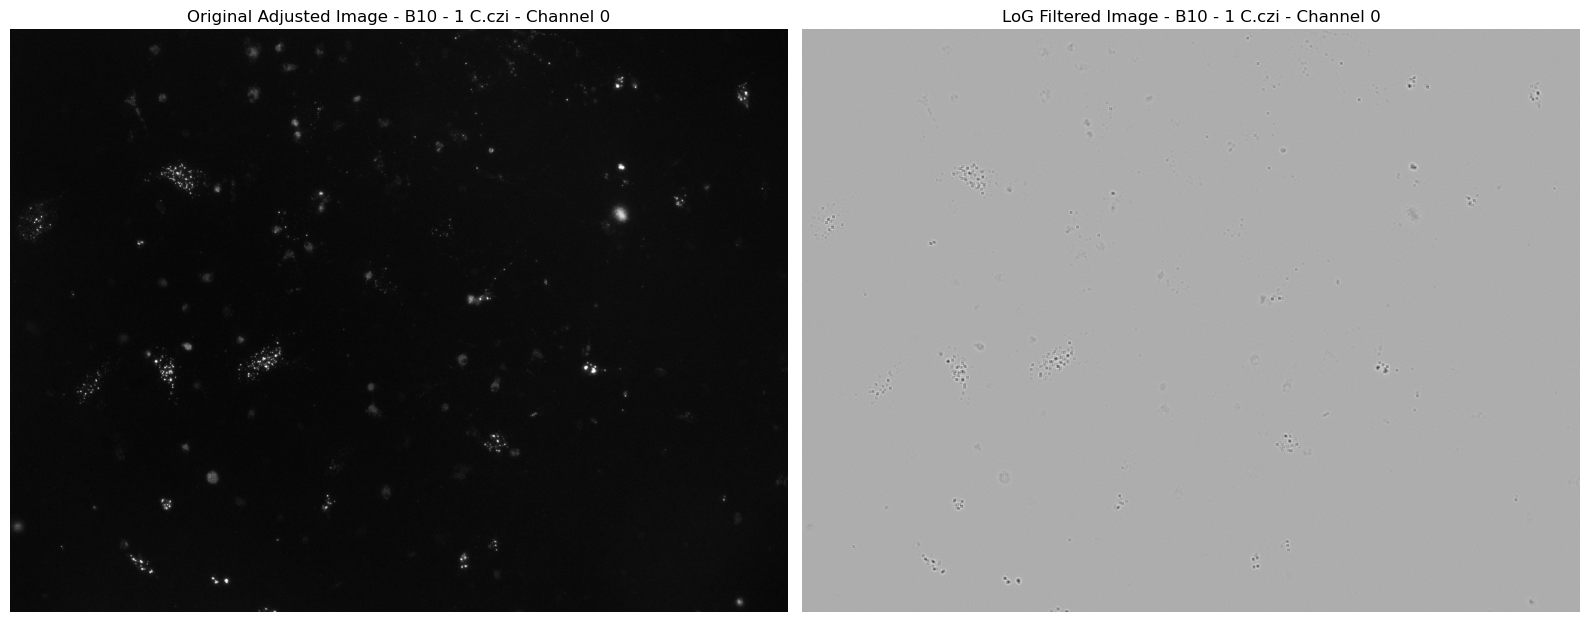

In [302]:
import cv2
import numpy as np

# Initialize dictionaries to store filtered images
filtered_images = {}

# Loop through each adjusted image in the dictionary
for filename, adjusted_channels in adjusted_images.items():
    # Initialize a list to store filtered channel images
    filtered_channels = []

    # Apply processing to each adjusted channel
    for channel_num in range(adjusted_channels.shape[0]):
        # Get the adjusted channel image
        adjusted_img = adjusted_channels[channel_num]

        # Apply Laplacian of Gaussian (LoG) filter
        log_filtered_img = cv2.Laplacian(cv2.GaussianBlur(adjusted_img, (5, 5), 5), cv2.CV_64F)

        # Store filtered image in the list
        filtered_channels.append(log_filtered_img)

    # Convert the list to a numpy array and store it in the dictionary
    filtered_images[filename] = np.array(filtered_channels)

# Access the filtered images using filtered_images[filename]

# Display an example image before and after filtering side by side
example_filename = next(iter(filtered_images.keys()))  # Get the filename of the first image in the filtered set

plt.figure(figsize=(16, 10))

# Original adjusted image
plt.subplot(1, 2, 1)
plt.imshow(adjusted_images[example_filename][0], cmap='gray')
plt.title(f"Original Adjusted Image - {example_filename} - Channel 0")
plt.axis('off')

# Filtered image using Laplacian of Gaussian (LoG)
plt.subplot(1, 2, 2)
plt.imshow(filtered_images[example_filename][0], cmap='gray')
plt.title(f"LoG Filtered Image - {example_filename} - Channel 0")
plt.axis('off')

# Adjust layout for better visualization
plt.tight_layout()
plt.show()

### Step 3: Thresholding

The idea at this point was to use the now filtered image, apply that function to the image set, and then proceed with thresholding. Although I had already done the filtering step, I wanted to create a function for it to make it more modular. 

In the thresholding step, I decided to start with a manual input of what the threshold values should be instead of implementing a function. The reason for this was so I could have more control over what features were retained, as opposed to a standard global thresholding function (binary threshold in python). The threshold values are input in the code directly.

#### Defining the functions

In [303]:
import cv2

def apply_filtering(adjusted_img):
    # Apply Laplacian of Gaussian (LoG) filter
    log_filtered_img = cv2.Laplacian(cv2.GaussianBlur(adjusted_img, (5, 5), 1.5), cv2.CV_64F)

    # Normalize the filtered image to [0, 255]
    normalized_img = cv2.normalize(log_filtered_img, None, 0, 255, cv2.NORM_MINMAX)

    return normalized_img

def apply_thresholding(filtered_img, threshold_value=170):
    # Apply thresholding
    _, thresholded_img = cv2.threshold(filtered_img, threshold_value, 255, cv2.THRESH_BINARY)

    return thresholded_img

#### Applying the functions to the image set

In [304]:
# Initialize dictionaries to store filtered and thresholded images
filtered_images = {}
thresholded_images = {}

# Define threshold values for each channel
threshold_values = {'Channel0': 160, 'Channel1': 180}  # Adjust these values based on your images

# Loop through each adjusted image in the dictionary
for filename, adjusted_channels in adjusted_images.items():
    # Initialize lists to store filtered and thresholded channel images
    filtered_channels = []
    thresholded_channels = []

    # Apply processing to each adjusted channel
    for channel_num in range(adjusted_channels.shape[0]):
        # Get the adjusted channel image
        adjusted_img = adjusted_channels[channel_num]

        # Apply filtering
        filtered_img = apply_filtering(adjusted_img)

        # Store filtered image in the list
        filtered_channels.append(filtered_img)

        # Get the channel name (assuming filenames follow the pattern "filename_channelX")
        channel_name = f'Channel{channel_num}'

        # Apply thresholding with channel-specific threshold value
        threshold_value = threshold_values.get(channel_name, 150)  # Default to 170 if not found
        thresholded_img = apply_thresholding(filtered_img, threshold_value)

        # Store thresholded image in the list
        thresholded_channels.append(thresholded_img)

    # Convert the lists to numpy arrays and store them in the dictionaries
    filtered_images[filename] = np.array(filtered_channels)
    thresholded_images[filename] = np.array(thresholded_channels)


#### Displaying an example image from the set

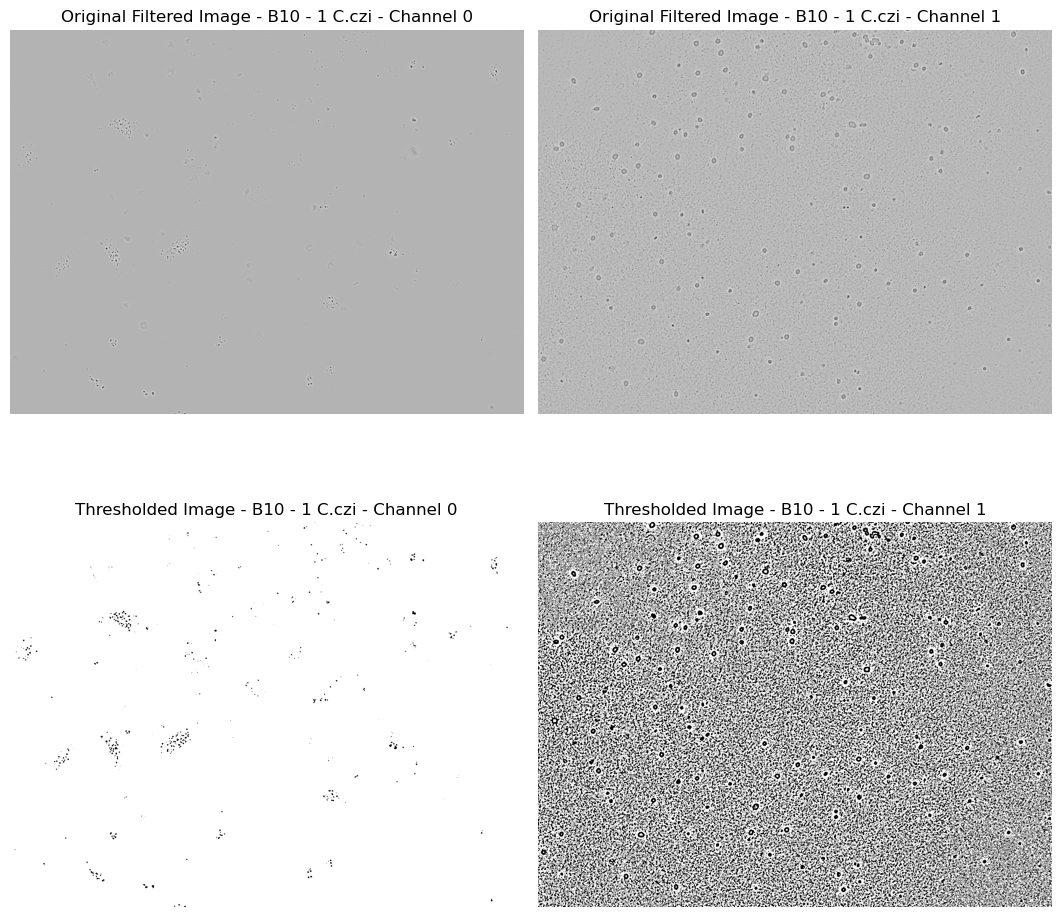

In [305]:
import matplotlib.pyplot as plt

# Display an example image before and after thresholding side by side
example_filename = next(iter(filtered_images.keys()))  # Get the filename of the first image in the filtered set

plt.figure(figsize=(16, 10))

# Loop through each channel
for channel_num in range(filtered_images[example_filename].shape[0]):
    # Original filtered image
    plt.subplot(2, 3, channel_num + 1)
    plt.imshow(filtered_images[example_filename][channel_num], cmap='gray')
    plt.title(f"Original Filtered Image - {example_filename} - Channel {channel_num}")
    plt.axis('off')

    # Thresholded image
    plt.subplot(2, 3, channel_num + 4)
    plt.imshow(thresholded_images[example_filename][channel_num], cmap='gray')
    plt.title(f"Thresholded Image - {example_filename} - Channel {channel_num}")
    plt.axis('off')

# Adjust layout for better visualization
plt.tight_layout()
plt.show()


I tried many different threshold values; 160 for channel 1 and 180 for channel 2 yielded the best results. The problem was that the images were not fully binary in either case. What I wanted was for the cells to be white and the background to be black (or vice versa). Only that way can we truly quantify them accurately. I decided to try and make the images binary from these filtered images.

In [306]:
# Initialize dictionaries to store binary, filtered, and thresholded images
binary_images = {}
filtered_images = {}
thresholded_images = {}

# Define threshold values for each channel
threshold_values = {'Channel0': 160, 'Channel1': 180}  # Adjust these values based on your images

# Loop through each adjusted image in the dictionary
for filename, adjusted_channels in adjusted_images.items():
    # Initialize lists to store binary, filtered, and thresholded channel images
    binary_channels = []
    filtered_channels = []
    thresholded_channels = []

    # Apply processing to each adjusted channel
    for channel_num in range(adjusted_channels.shape[0]):
        # Get the adjusted channel image
        adjusted_img = adjusted_channels[channel_num]

        # Apply filtering
        filtered_img = apply_filtering(adjusted_img)

        # Convert the filtered image to binary
        _, binary_img = cv2.threshold(filtered_img, 0, 255, cv2.THRESH_BINARY)

        # Store binary image in the list
        binary_channels.append(binary_img)

        # Store filtered image in the list
        filtered_channels.append(filtered_img)

        # Get the channel name (assuming filenames follow the pattern "filename_channelX")
        channel_name = f'Channel{channel_num}'

        # Apply thresholding with channel-specific threshold value
        threshold_value = threshold_values.get(channel_name, 160)  # Default to 170 if not found
        thresholded_img = apply_thresholding(filtered_img, threshold_value)

        # Store thresholded image in the list
        thresholded_channels.append(thresholded_img)

    # Convert the lists to numpy arrays and store them in the dictionaries
    binary_images[filename] = np.array(binary_channels)
    filtered_images[filename] = np.array(filtered_channels)
    thresholded_images[filename] = np.array(thresholded_channels)


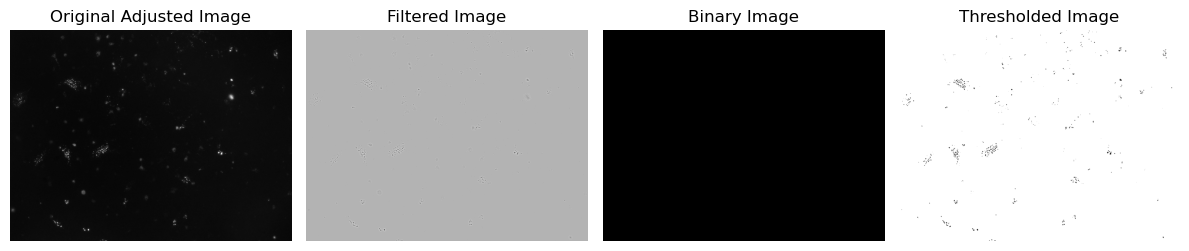

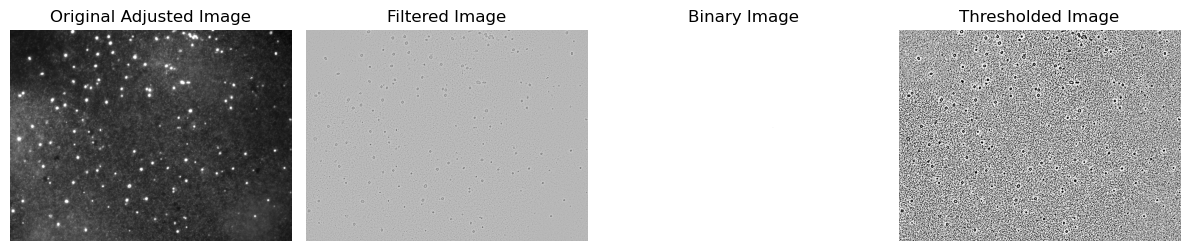

In [307]:
import matplotlib.pyplot as plt

# Function to display images
def display_images(images, titles, figsize=(12, 8), cmap='gray', rows=1, cols=None):
    if cols is None:
        cols = len(images)

    plt.figure(figsize=figsize)
    
    for i in range(len(images)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(images[i], cmap=cmap)
        plt.title(titles[i])
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# Choose an example filename
example_filename = next(iter(adjusted_images.keys()))

# Display an example image for each step in both channels
for channel_num in range(adjusted_images[example_filename].shape[0]):
    # Get images for the current channel
    adjusted_img = adjusted_images[example_filename][channel_num]
    filtered_img = filtered_images[example_filename][channel_num]
    binary_img = binary_images[example_filename][channel_num]
    thresholded_img = thresholded_images[example_filename][channel_num]

    # Prepare images and titles for display
    images_to_display = [adjusted_img, filtered_img, binary_img, thresholded_img]
    titles = ["Original Adjusted Image", "Filtered Image", "Binary Image", "Thresholded Image"]

    # Display the images
    display_images(images_to_display, titles, rows=1, cols=len(images_to_display))

That obviously didn't work. The filtering caused the binary thresholding function I used to be completely blind to the particles. The thresholded image on the right is just the one obtained with manually input threshold values. I decided to try and apply thresholding directly to the brightness adjusted images, skipping the filtering step. The idea was to retain as much of the original image as possible, given that I seemingly lost too much of it through filtering and impeded the thresholding process.

I chose to proceed with Otsu's thresholding. In essence, calculating a threshold using Otsu’s method involves adding the variance of the background pixels to the variance of the foreground pixels, for all possible thresholds. The threshold that is selected is the one for which the sum of the variances is smallest. We can think of this as trying to keep the distributions of foreground and background pixels ‘compact’: two peaks that spread as little as possible.

Otsu’s method performs very well on data with a bimodal histogram, with a deep valley in between. Unfortunately, a lot of microscopy images don’t have clearly bimodal histograms, and so the method may not be such a good choice. I tried it here because grayscale images from a live/dead assay could lend themselves well to this method.

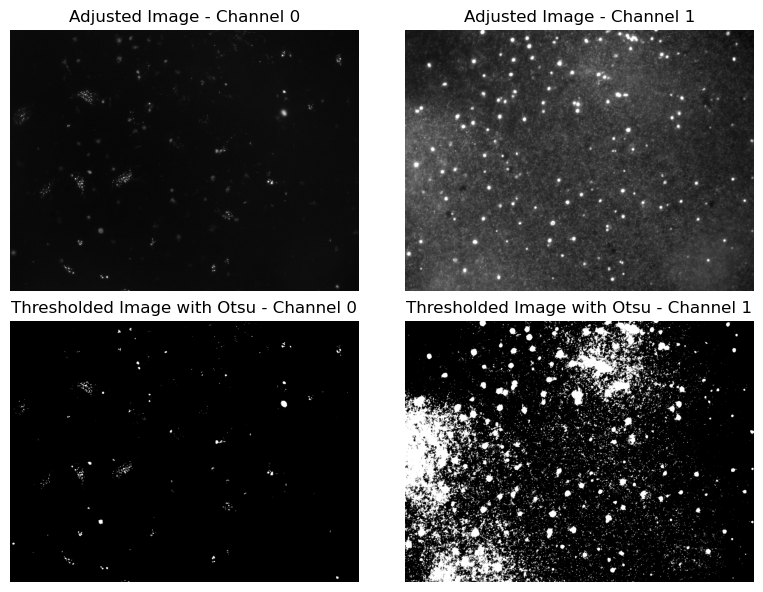

In [308]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Create a dictionary to store thresholded images
otsu_thresholded_images = {}

# Loop through each adjusted image in the dictionary
for filename, adjusted_channels in adjusted_images.items():
    # Initialize lists to store adjusted and thresholded channel images
    adjusted_channels_list = []
    otsu_thresholded_channels_list = []

    # Apply Otsu's thresholding to each adjusted channel
    for channel_num in range(adjusted_channels.shape[0]):
        # Get the adjusted channel image
        adjusted_img = adjusted_channels[channel_num]

        # Apply Otsu's thresholding
        _, thresholded_img = cv2.threshold(adjusted_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

        # Store adjusted and thresholded images in the lists
        adjusted_channels_list.append(adjusted_img)
        otsu_thresholded_channels_list.append(thresholded_img)

    # Convert the lists to numpy arrays and store them in the dictionaries
    otsu_thresholded_images[filename] = np.array(otsu_thresholded_channels_list)

# Display an example image from the new dictionary
example_filename_otsu = next(iter(otsu_thresholded_images.keys()))

# Display the adjusted and thresholded images for an example image in both channels
plt.figure(figsize=(12, 6))

# Adjusted images
plt.subplot(2, 3, 1)
plt.imshow(adjusted_images[example_filename_otsu][0], cmap='gray')
plt.title("Adjusted Image - Channel 0")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(adjusted_images[example_filename_otsu][1], cmap='gray')
plt.title("Adjusted Image - Channel 1")
plt.axis('off')

# Thresholded images with Otsu
plt.subplot(2, 3, 4)
plt.imshow(otsu_thresholded_images[example_filename_otsu][0], cmap='gray')
plt.title("Thresholded Image with Otsu - Channel 0")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(otsu_thresholded_images[example_filename_otsu][1], cmap='gray')
plt.title("Thresholded Image with Otsu - Channel 1")
plt.axis('off')

plt.tight_layout()
plt.show()

#### New method, same deal

I realized way down into this rabbit hole that I never tried adapting the sigma value of the Gaussian blur using those filtered images to threshold. I tried doing that here; basically I did exactly what I did above, but instead of using a LoG filter I used a Gaussian blur before thresholding.

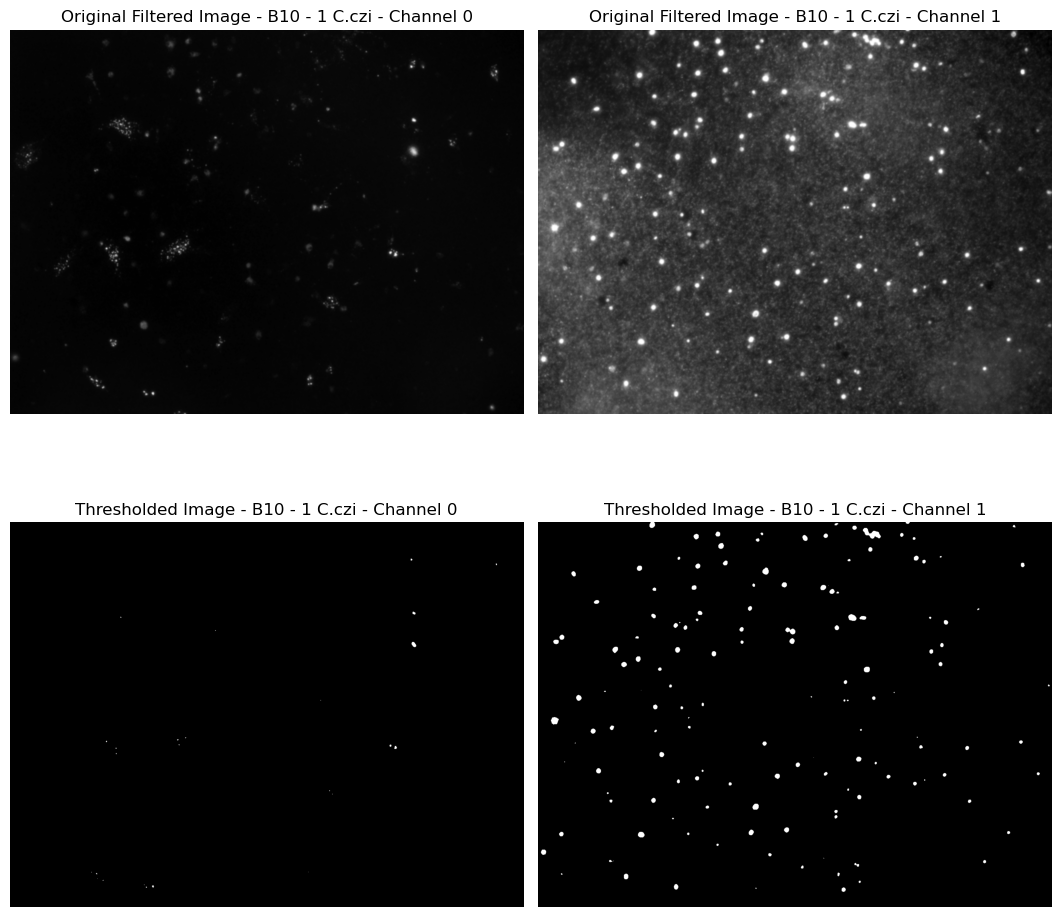

In [309]:
import cv2

def apply_filtering(adjusted_img):
    # Apply Gaussian Blur
    log_filtered_img = cv2.GaussianBlur(adjusted_img, (5, 5), 1.5) #This time, I used a Gaussian blur

    # Normalize the filtered image to [0, 255]
    normalized_img = cv2.normalize(log_filtered_img, None, 0, 255, cv2.NORM_MINMAX)

    return normalized_img

def apply_thresholding(filtered_img, threshold_value=170):
    # Apply thresholding
    _, thresholded_img = cv2.threshold(filtered_img, threshold_value, 255, cv2.THRESH_BINARY)

    return thresholded_img

# Initialize dictionaries to store filtered and thresholded images
filtered_images = {}
thresholded_images = {}

# Define threshold values for each channel
threshold_values = {'Channel0': 160, 'Channel1': 180}  # Adjust these values based on your images

# Loop through each adjusted image in the dictionary
for filename, adjusted_channels in adjusted_images.items():
    # Initialize lists to store filtered and thresholded channel images
    filtered_channels = []
    thresholded_channels = []

    # Apply processing to each adjusted channel
    for channel_num in range(adjusted_channels.shape[0]):
        # Get the adjusted channel image
        adjusted_img = adjusted_channels[channel_num]

        # Apply filtering
        filtered_img = apply_filtering(adjusted_img)

        # Store filtered image in the list
        filtered_channels.append(filtered_img)

        # Get the channel name (assuming filenames follow the pattern "filename_channelX")
        channel_name = f'Channel{channel_num}'

        # Apply thresholding with channel-specific threshold value
        threshold_value = threshold_values.get(channel_name, 150)  # Default to 170 if not found
        thresholded_img = apply_thresholding(filtered_img, threshold_value)

        # Store thresholded image in the list
        thresholded_channels.append(thresholded_img)

    # Convert the lists to numpy arrays and store them in the dictionaries
    filtered_images[filename] = np.array(filtered_channels)
    thresholded_images[filename] = np.array(thresholded_channels)

    
    # Display an example image before and after thresholding side by side
example_filename = next(iter(filtered_images.keys()))  # Get the filename of the first image in the filtered set

plt.figure(figsize=(16, 10))

# Loop through each channel
for channel_num in range(filtered_images[example_filename].shape[0]):
    # Original filtered image
    plt.subplot(2, 3, channel_num + 1)
    plt.imshow(filtered_images[example_filename][channel_num], cmap='gray')
    plt.title(f"Original Filtered Image - {example_filename} - Channel {channel_num}")
    plt.axis('off')

    # Thresholded image
    plt.subplot(2, 3, channel_num + 4)
    plt.imshow(thresholded_images[example_filename][channel_num], cmap='gray')
    plt.title(f"Thresholded Image - {example_filename} - Channel {channel_num}")
    plt.axis('off')

# Adjust layout for better visualization
plt.tight_layout()
plt.show()


These thresholded images, particularly in the live cell channel, look much cleaner than when I applied the Otsu thresdhold to the raw brightness adjusted image (the non-filtered one). I decided to continue with these images.

### Step 4: Applying the Watershed function

Looking at the thresholded images, it becomes clear that some particles are "stuck together". That will make it tricky to quantify accurate cell counts in later steps, so I needed to implement a watershed function to delineated touching particles and separate them. I looked into what watershed functions were available and landed on the broadly used skimage version.

#### Thresholding & Watershed Function Explanation
After applying the watershed function, the resulting images show segmented objects. The watershed algorithm is used for image segmentation and is particularly useful for separating touching or overlapping objects. The segmentation is based on the intensity or color differences in the original image.

Here's a breakdown of what you see in the displayed images:

* Thresholded Images with Otsu: These are the binary images obtained after applying Otsu's thresholding to the original images.

* Watershed Images:These images result from applying the watershed algorithm to the corresponding thresholded images.

The distinct colors represent different segments or regions separated by the algorithm.
The idea is that the watershed algorithm helps identify and separate different objects in the image. Each colored region in the watershed image corresponds to a different segment, indicating a distinct object or region in the original image. The choice of colormap (cmap) in the plt.imshow function can affect how these segments are visualized.

C:\Users\aless\AppData\Local\Temp\ipykernel_49404\2584060369.py:27: FutureWarning: indices argument is deprecated and will be removed in version 0.20. To avoid this warning, please do not use the indices argument. Please see peak_local_max documentation for more details.
  markers = peak_local_max(distance, indices=False, labels=local_max)


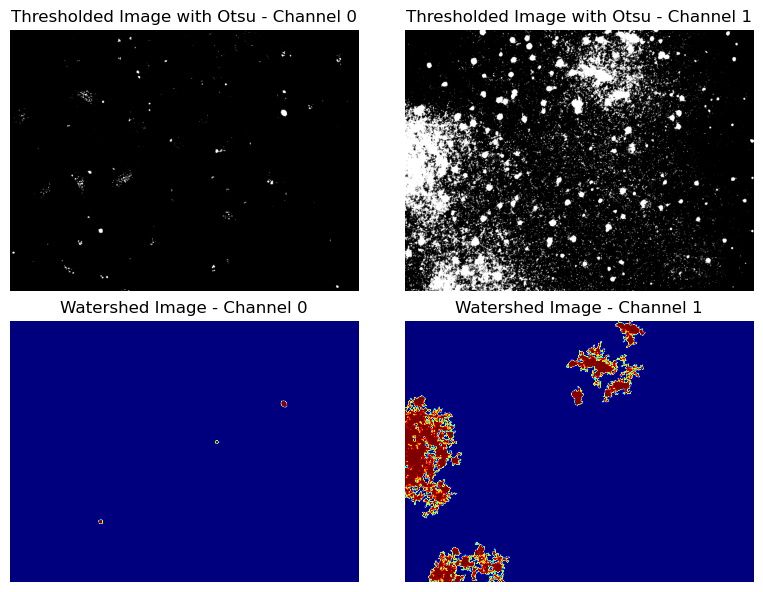

In [310]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.segmentation import watershed
from skimage.feature import peak_local_max

# Assuming otsu_thresholded_images is your dictionary of binary thresholded images
# Create a dictionary to store watershed images
watershed_images = {}

# Loop through each thresholded image in the dictionary
for filename, thresholded_channels in otsu_thresholded_images.items():
    # Initialize lists to store watershed channel images
    watershed_channels_list = []

    # Apply watershed segmentation to each thresholded channel
    for channel_num in range(thresholded_channels.shape[0]):
        # Get the thresholded channel image
        thresholded_img = thresholded_channels[channel_num]

        # Apply watershed algorithm
        distance = cv2.distanceTransform(thresholded_img, cv2.DIST_L2, 5)
        _, local_max = cv2.threshold(distance, 0.5 * distance.max(), 255, 0)
        local_max = local_max.astype(np.uint8)

        # Find peaks in the distance map
        markers = peak_local_max(distance, indices=False, labels=local_max)

        # Apply watershed segmentation
        labels = watershed(-distance, markers, mask=thresholded_img)

        # Store watershed image in the list
        watershed_channels_list.append(labels)

    # Convert the list to a numpy array and store it in the dictionary
    watershed_images[filename] = np.array(watershed_channels_list)

# Display an example image from the new dictionary
example_filename_watershed = next(iter(watershed_images.keys()))

# Display the watershed images for an example image in both channels
plt.figure(figsize=(12, 6))

# Thresholded images with Otsu
plt.subplot(2, 3, 1)
plt.imshow(otsu_thresholded_images[example_filename_watershed][0], cmap='gray')
plt.title("Thresholded Image with Otsu - Channel 0")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(otsu_thresholded_images[example_filename_watershed][1], cmap='gray')
plt.title("Thresholded Image with Otsu - Channel 1")
plt.axis('off')

# Watershed images
plt.subplot(2, 3, 4)
plt.imshow(watershed_images[example_filename_watershed][0], cmap='jet')  # cmap='jet' for better visualization
plt.title("Watershed Image - Channel 0")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(watershed_images[example_filename_watershed][1], cmap='jet')  # cmap='jet' for better visualization
plt.title("Watershed Image - Channel 1")
plt.axis('off')

plt.tight_layout()
plt.show()


This was a good start, but it seemed that the watershed function was being a bit too conservative with the features it was recognizing, and doing a poor job of actually separating particles that were stuck together. I looked into what function parameters I could modulate to improve the results. Here are some helpful tips:
* Adjust Distance Transform Parameters: The parameters of the distance transform (e.g., the size of the neighborhood for the distance transform) can significantly impact the results. Experimenting with different parameter values could improve the segmentation.
* Adjust Thresholding: The threshold applied to the distance transform result (0.5 * distance.max()) might not be optimal for all images. Experimenting with different threshold values could improve the identification of markers.
* Adjust Peak Local Max Parameters: The peak_local_max function also has parameters that can be adjusted. For example, trying different footprint sizes controls how local maxima are identified.
* Preprocess Images: Depending on the nature of your images, further preprocess them before applying watershed segmentation might be necessary. I didn't further preprocess here, because I felt they were sufficiently processed.


C:\Users\aless\AppData\Local\Temp\ipykernel_49404\2953254839.py:20: FutureWarning: indices argument is deprecated and will be removed in version 0.20. To avoid this warning, please do not use the indices argument. Please see peak_local_max documentation for more details.
  markers = peak_local_max(distance, indices=False, labels=local_max, footprint=np.ones((10, 10)))  # Adjust footprint


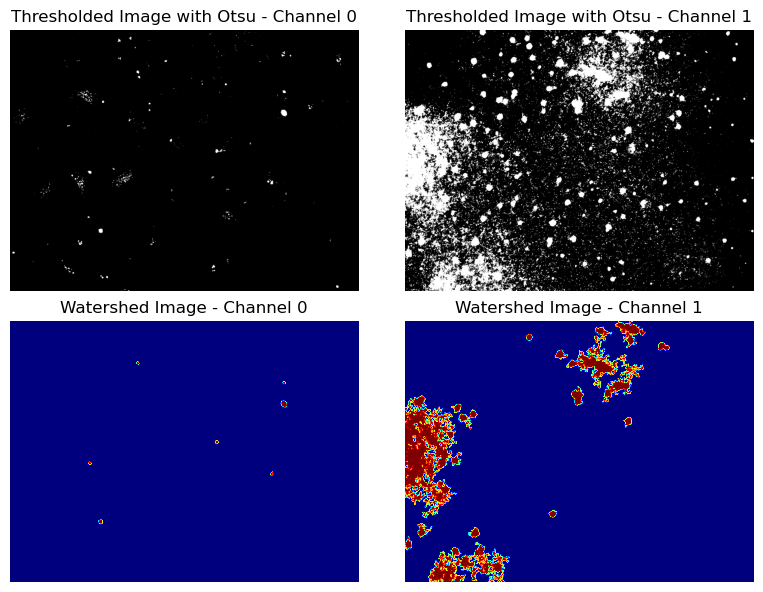

In [311]:
# Create a dictionary to store watershed images
watershed_images = {}

# Loop through each thresholded image in the dictionary
for filename, thresholded_channels in otsu_thresholded_images.items():
    # Initialize lists to store watershed channel images
    watershed_channels_list = []

    # Apply watershed segmentation to each thresholded channel
    for channel_num in range(thresholded_channels.shape[0]):
        # Get the thresholded channel image
        thresholded_img = thresholded_channels[channel_num]

        # Apply watershed algorithm
        distance = cv2.distanceTransform(thresholded_img, cv2.DIST_L2, 3)  # Adjust neighborhood size
        _, local_max = cv2.threshold(distance, 0.4 * distance.max(), 255, 0)  # Adjust threshold
        local_max = local_max.astype(np.uint8)

        # Find peaks in the distance map
        markers = peak_local_max(distance, indices=False, labels=local_max, footprint=np.ones((10, 10)))  # Adjust footprint

        # Apply watershed segmentation
        labels = watershed(-distance, markers, mask=thresholded_img)

        # Store watershed image in the list
        watershed_channels_list.append(labels)

    # Convert the list to a numpy array and store it in the dictionary
    watershed_images[filename] = np.array(watershed_channels_list)

# Display an example image from the new dictionary
example_filename_watershed = next(iter(watershed_images.keys()))

# Display the watershed images for an example image in both channels
plt.figure(figsize=(12, 6))

# Thresholded images with Otsu
plt.subplot(2, 3, 1)
plt.imshow(otsu_thresholded_images[example_filename_watershed][0], cmap='gray')
plt.title("Thresholded Image with Otsu - Channel 0")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(otsu_thresholded_images[example_filename_watershed][1], cmap='gray')
plt.title("Thresholded Image with Otsu - Channel 1")
plt.axis('off')

# Watershed images
plt.subplot(2, 3, 4)
plt.imshow(watershed_images[example_filename_watershed][0], cmap='jet')  # cmap='jet' for better visualization
plt.title("Watershed Image - Channel 0")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(watershed_images[example_filename_watershed][1], cmap='jet')  # cmap='jet' for better visualization
plt.title("Watershed Image - Channel 1")
plt.axis('off')

plt.tight_layout()
plt.show()


Adjusting helped, but channel 0 still showed poor segmentation of cells that are clearly stuck together. I noticed that the algorithm is quite good at separating small, round particles that are stuck together, but bigger particles with far less circularity (yet quite obviously multiple particles stuck together) are not recognized at all. I focused on watershed functions specifically for channel 0 to tailor the approach to different types of particles.

I tried using the skimage.segmentation.watershed function directly with a different approach. The idea is to use gradient information to identify markers for the watershed algorithm.

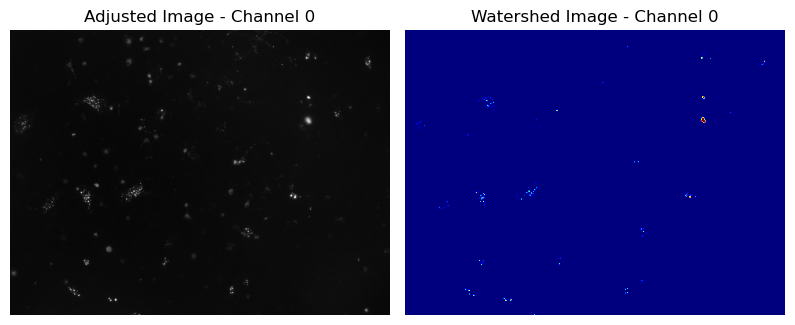

In [312]:
from skimage.filters import sobel
from skimage.segmentation import watershed
from skimage.measure import label
from skimage.color import label2rgb

# Assuming adjusted_images is your dictionary of brightness adjusted images
# Create a dictionary to store watershed images
watershed_images_channel0 = {}

# Loop through each adjusted image in the dictionary
for filename, adjusted_channels in adjusted_images.items():
    # Get the adjusted channel image for Channel 0
    adjusted_img_channel0 = adjusted_channels[0]

    # Apply Sobel filter to get gradient information
    gradient_0 = sobel(adjusted_img_channel0)

    # Generate markers based on gradient information
    markers_0 = np.zeros_like(adjusted_img_channel0)
    markers_0[adjusted_img_channel0 > 0.9 * adjusted_img_channel0.max()] = 2 #Adjust to control thresholds for creating markers. Higher values create values for brighter regions
    markers_0[adjusted_img_channel0 < 0.3 * adjusted_img_channel0.max()] = 1 #Lower values create markers for darker regions

    # Apply watershed segmentation
    labels_0 = watershed(gradient_0, markers_0, mask=adjusted_img_channel0)
    
    # Adjust watershed parameters
    #labels_0 = watershed(gradient, markers, mask=adjusted_img_channel0, compactness=0.0008, watershed_line=True) 
    #You can control the behavior of the algorithm with these parameters. I played around with it but pretty unsuccessful...

    # Store watershed image in the dictionary
    watershed_images_channel0[filename] = labels_0

# Display an example image from the new dictionary
example_filename_watershed_channel0 = next(iter(watershed_images_channel0.keys()))

# Display the watershed images for an example image in Channel 0
plt.figure(figsize=(12, 6))

# Adjusted image for Channel 0
plt.subplot(1, 3, 1)
plt.imshow(adjusted_images[example_filename_watershed_channel0][0], cmap='gray')
plt.title("Adjusted Image - Channel 0")
plt.axis('off')

# Watershed image for Channel 0
plt.subplot(1, 3, 2)
plt.imshow(watershed_images_channel0[example_filename_watershed_channel0], cmap='jet')  # cmap='jet' for better visualization
plt.title("Watershed Image - Channel 0")
plt.axis('off')

plt.tight_layout()
plt.show()

Here, "compactness" controls the trade-off between color-based and spatial-based cues in the watershed algorithm. Smaller values lead to more color-based segmentation, while larger values result in more spatial-based segmentation. You can experiment with different values to find what works best for the images.

Additionally, setting "watershed_line=True" can help in delineating the boundaries between segmented regions. Adjust these parameters and observe their effects on the segmentation results.

To better understand the segmentation result, I overlayed the watershed boundaries on top of the thresholded image (you can also do this over the original or adjusted image). This will allow you to visualize how the algorithm has separated different regions. 

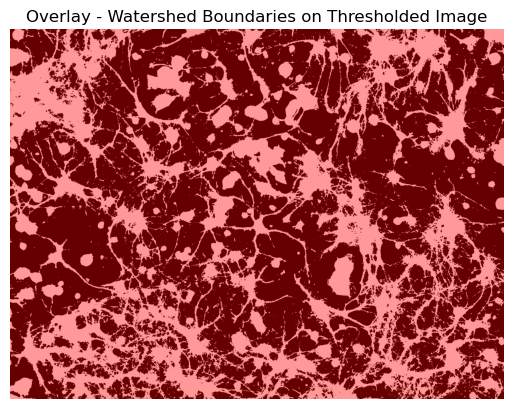

In [313]:
from skimage.color import label2rgb

thresholded_img_channel0 = thresholded_channels[0]

# Apply Sobel filter to get gradient
gradient_channel0 = sobel(adjusted_img_channel0)

# Apply watershed algorithm
labels_channel0 = watershed(gradient_0, markers_0, mask=adjusted_img_channel0)

# Overlay watershed boundaries on the original image
overlay_channel0 = label2rgb(labels_0, image=thresholded_img_channel0, bg_label=0, alpha=0.4, bg_color=[1, 1, 1])

# Display the result
plt.imshow(overlay_channel0)
plt.title("Overlay - Watershed Boundaries on Thresholded Image")
plt.axis('off')
plt.show()

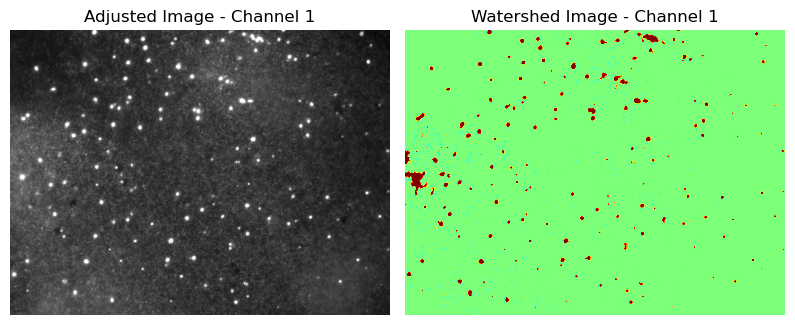

In [314]:
from skimage.filters import sobel
from skimage.segmentation import watershed
from skimage.measure import label
from skimage.color import label2rgb

# Assuming adjusted_images is your dictionary of brightness adjusted images
# Create a dictionary to store watershed images for Channel 1
watershed_images_channel1 = {}

# Loop through each adjusted image in the dictionary
for filename, adjusted_channels in adjusted_images.items():
    # Get the adjusted channel image for Channel 1
    adjusted_img_channel1 = adjusted_channels[1]

    # Apply Sobel filter to get gradient information
    gradient_1 = sobel(adjusted_img_channel1)

    # Generate markers based on gradient information
    markers_1 = np.zeros_like(adjusted_img_channel1)
    markers_1[adjusted_img_channel1 > 0.6 * adjusted_img_channel1.max()] = 2  # Adjust to control thresholds for creating markers. Higher values create values for brighter regions
    markers_1[adjusted_img_channel1 < 0.4 * adjusted_img_channel1.max()] = 1  # Lower values create markers for darker regions

    # Apply watershed segmentation
    # labels = watershed(gradient, markers, mask=adjusted_img_channel1)

    # Adjust watershed parameters if needed
    labels_1 = watershed(gradient_1, markers_1, mask=adjusted_img_channel1, compactness=0.0003, watershed_line=True)
    # You can control the behavior of the algorithm with these parameters. 
    
    # Store watershed image in the dictionary
    watershed_images_channel1[filename] = labels_1

# Display an example image from the new dictionary
example_filename_watershed_channel1 = next(iter(watershed_images_channel1.keys()))

# Display the watershed images for an example image in Channel 1
plt.figure(figsize=(12, 6))

# Adjusted image for Channel 1
plt.subplot(1, 3, 1)
plt.imshow(adjusted_images[example_filename_watershed_channel1][1], cmap='gray')
plt.title("Adjusted Image - Channel 1")
plt.axis('off')

# Watershed image for Channel 1
plt.subplot(1, 3, 2)
plt.imshow(watershed_images_channel1[example_filename_watershed_channel1], cmap='jet')  # cmap='jet' for better visualization
plt.title("Watershed Image - Channel 1")
plt.axis('off')

plt.tight_layout()
plt.show()


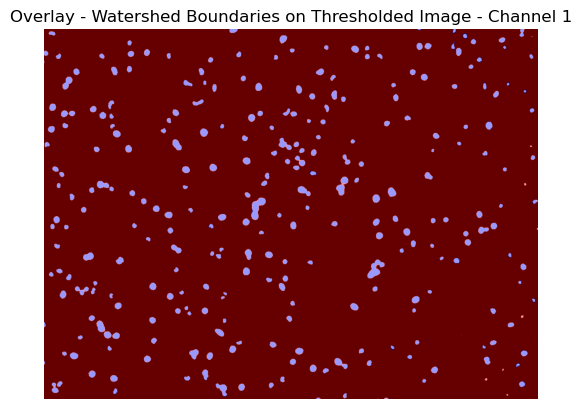

In [315]:
from skimage.color import label2rgb

thresholded_img_channel1 = thresholded_channels[1]

# Apply Sobel filter to get gradient for Channel 1
gradient_channel1 = sobel(adjusted_img_channel1)

# Apply watershed algorithm for Channel 1
labels_channel1 = watershed(gradient_1, markers_1, mask=adjusted_img_channel1)

# Overlay watershed boundaries on the original image for Channel 1
overlay_channel1 = label2rgb(labels_channel1, image=thresholded_img_channel1, bg_label=0, alpha=0.4, bg_color=[1, 1, 1])

# Display the result for Channel 1
plt.imshow(overlay_channel1)
plt.title("Overlay - Watershed Boundaries on Thresholded Image - Channel 1")
plt.axis('off')
plt.show()


This worked pretty well. It's not perfect, but no watershed function will be. I think it is better for us to underestimate the number of cells we have in each image rather than overestimate; it will make the readout from the live/dead assay less positively biased. I think the algorithm did a pretty good job at separating the main features. Some are less obvious, particularly in channel 0 (EGFP channel). There are still a few "chunks" of cells, but I focused on counting the cells that were separate and easy to recognize rather than trying on segmenting as closely as possible; I didn't want to "overfit" the watershed function to this specific image, and tried to get it to be as accurate as possible across the set.

### Step 5: Quantifying ROIs and Live/Dead Ratios

Now, we have all the tools we need. We just need to count the regions that we delineated and defined by the watershed function. Once we have them quantified, we can calculate the following ratio:

    #ROIs in CalceinAM channel (live cells)/ #ROIs in DAPI channel (total cells)
    
I will save the data in a dataframe, so we can then analyze the data more easily, and trace it back to the plate map.

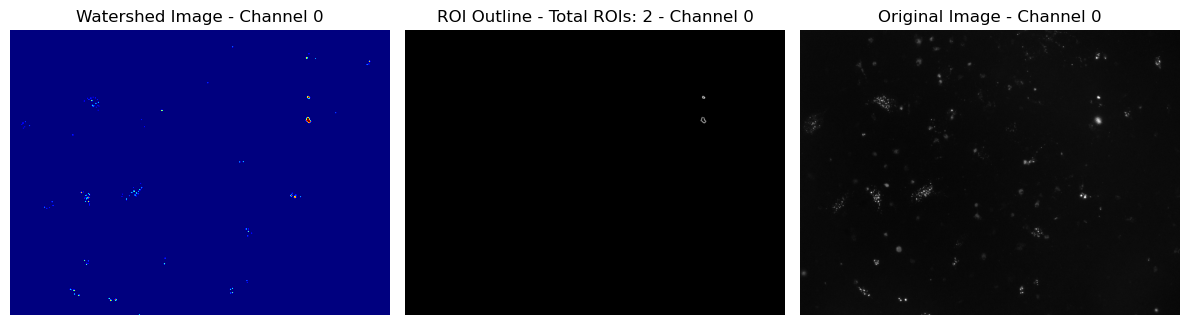

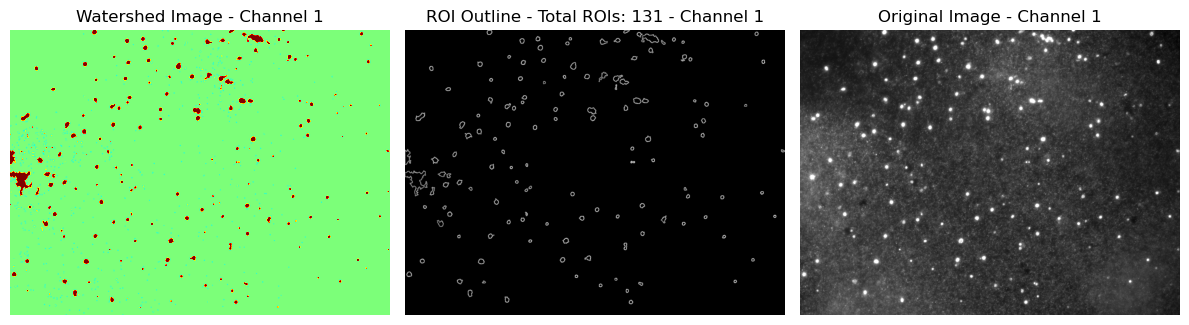

In [316]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create dictionaries to store ROI counts
roi_counts_channel0 = {}
roi_counts_channel1 = {}

# Define a function to quantify ROIs
def quantify_rois(watershed_images, channel_threshold):
    roi_counts = {}
    
    # Loop through each watershed image in the dictionary
    for filename, watershed_img in watershed_images.items():
        # Apply a threshold to the watershed image to create binary ROIs
        _, binary_img = cv2.threshold(watershed_img.astype(np.uint8), 1, 255, cv2.THRESH_BINARY)
        
        # Find contours in the binary image
        contours, _ = cv2.findContours(binary_img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        
        # Filter out small ROIs (adjust the area threshold as needed)
        min_area = 50
        valid_contours = [contour for contour in contours if cv2.contourArea(contour) > min_area]
        
        # Count the total number of ROIs
        total_rois = len(valid_contours)
        
        # Create an empty mask for visualization
        mask = np.zeros_like(binary_img)
        
        # Draw the delineation of valid ROIs with a visible color
        cv2.drawContours(mask, valid_contours, -1, (255), thickness=2)
        
        # Overlay the mask on the channel image for visualization
        overlay = cv2.bitwise_and(channel_threshold, channel_threshold, mask=mask)
        
        # Store the count and visualization in the dictionary
        roi_counts[filename] = (total_rois, overlay)
    
    return roi_counts

# Get the first filename from the watershed images dictionary for Channel 0
example_filename_channel0 = next(iter(watershed_images_channel0.keys()))

# Quantify ROIs for Channel 0 using watershed images
roi_counts_channel0 = quantify_rois(watershed_images_channel0, adjusted_images[example_filename_channel0][0])

# Get the first filename from the watershed images dictionary for Channel 1
example_filename_channel1 = next(iter(watershed_images_channel1.keys()))

# Quantify ROIs for Channel 1 using watershed images
roi_counts_channel1 = quantify_rois(watershed_images_channel1, adjusted_images[example_filename_channel1][1])

# Display an example image for Channel 0
total_rois_channel0, roi_outline_channel0 = roi_counts_channel0[example_filename_channel0]

plt.figure(figsize=(12, 6))

# Watershed image for Channel 0
plt.subplot(1, 3, 1)
plt.imshow(watershed_images_channel0[example_filename_channel0], cmap='jet')  # cmap='jet' for better visualization
plt.title("Watershed Image - Channel 0")
plt.axis('off')

# ROI Outline for Channel 0
plt.subplot(1, 3, 2)
plt.imshow(roi_outline_channel0, cmap='gray')
plt.title(f"ROI Outline - Total ROIs: {total_rois_channel0} - Channel 0")
plt.axis('off')

# Original Channel 0 image
plt.subplot(1, 3, 3)
plt.imshow(adjusted_images[example_filename_channel0][0], cmap='gray')
plt.title("Original Image - Channel 0")
plt.axis('off')

plt.tight_layout()
plt.show()

# Display an example image for Channel 1
total_rois_channel1, roi_outline_channel1 = roi_counts_channel1[example_filename_channel1]

plt.figure(figsize=(12, 6))

# Watershed image for Channel 1
plt.subplot(1, 3, 1)
plt.imshow(watershed_images_channel1[example_filename_channel1], cmap='jet')  # cmap='jet' for better visualization
plt.title("Watershed Image - Channel 1")
plt.axis('off')

# ROI Outline for Channel 1
plt.subplot(1, 3, 2)
plt.imshow(roi_outline_channel1, cmap='gray')
plt.title(f"ROI Outline - Total ROIs: {total_rois_channel1} - Channel 1")
plt.axis('off')

# Original Channel 1 image
plt.subplot(1, 3, 3)
plt.imshow(adjusted_images[example_filename_channel1][1], cmap='gray')
plt.title("Original Image - Channel 1")
plt.axis('off')

plt.tight_layout()
plt.show()


#### Creating the dataframe

In [317]:
import pandas as pd
import re

# Update the regex pattern to match both formats and capture the contamination status
def parse_filename(filename):
    match = re.match(r'([A-Z]\d+) - (\d+)( C)?\.czi', filename, re.IGNORECASE)
    if match:
        well_id, replicate, contaminated = match.groups()
        # Assign 'C' if contaminated, 'N' if not
        status = 'C' if contaminated else 'N'
        return well_id, replicate, status
    else:
        return None, None, 'N'  # Default to 'N' if pattern does not match

data = []

# Loop through the filenames in the roi counts dictionaries
for filename in roi_counts_channel0.keys():
    # Extract well ID, replicate, and contamination status from the filename
    well_id, replicate, status = parse_filename(filename)
    
    # Get the number of ROIs for each channel
    num_rois_channel0 = roi_counts_channel0[filename][0]
    num_rois_channel1 = roi_counts_channel1[filename][0]
    
    # Calculate the ratio and percentage
    ratio = num_rois_channel0 / num_rois_channel1 if num_rois_channel1 else 0
    percentage = ratio * 100
    
    # Append the data to the list
    data.append([well_id, replicate, status, num_rois_channel0, num_rois_channel1, ratio, percentage])

# Create a DataFrame with the data
df = pd.DataFrame(data, columns=['Well ID', 'Replicate', 'Contaminated', 'Number of ROIs Channel 0', 
                                 'Number of ROIs Channel 1', 'Ratio', 'Percentage'])

df

,Well ID,Replicate,Contaminated,Number of ROIs Channel 0,Number of ROIs Channel 1,Ratio,Percentage
0,B10,1,C,2,131,0.015267,1.526718
1,B10,2,C,6,147,0.040816,4.081633
2,B10,3,C,2,182,0.010989,1.098901
3,B11,1,C,19,192,0.098958,9.895833
4,B11,2,C,13,193,0.067358,6.735751
...,...,...,...,...,...,...,...
175,G8,2,C,54,326,0.165644,16.564417
176,G8,3,C,26,162,0.160494,16.049383
177,G9,1,N,1,306,0.003268,0.326797
178,G9,2,N,1,269,0.003717,0.371747


##### Making sure the dataframe doesn't contain null values or unmatched files

In [318]:
# Create a boolean Series indicating rows with NaN values
rows_with_nan = df.isna().any(axis=1)

# Filter the DataFrame to show only rows with NaN values
nan_rows = df[rows_with_nan]
nan_rows

,Well ID,Replicate,Contaminated,Number of ROIs Channel 0,Number of ROIs Channel 1,Ratio,Percentage


In [319]:
unmatched_filenames = []

# Loop through the filenames
for filename in roi_counts_channel0.keys():
    # Apply the parse_filename function
    well_id, replicate, status = parse_filename(filename)
    
    # Check if any part of the parsed result is None
    if well_id is None or replicate is None:
        unmatched_filenames.append(filename)

# Now print all unmatched filenames
print("Unmatched filenames:")
for fname in unmatched_filenames:
    print(fname)


Unmatched filenames:


#### Contaminated Rows

In [320]:
contaminated_rows = df[df['Contaminated'] == 'C']
contaminated_count = len(contaminated_rows)
print(f"Number of contaminated rows: {contaminated_count}")

Number of contaminated rows: 93


#### Rows with Live/Dead Ratios over 100

I realized as I saw the ratios that for some images, the number of live cells exceeds the number of total cells. Obviously that is an artefact, of both the image processing but also the images themselves. The stains are imperfect, and it's not always trivial to get clear differentiation. 
I thought about how to best handle those cases. I first tried to assess how many rows were affected by this to see if there was any major issue with the image processing.

In [321]:
count_exceeding_100 = (df['Percentage'] > 100).sum()
print(f"Number of wells with a Live/Dead Ratio over 100:   {count_exceeding_100}")

count_contaminated_and_percentage_over_100 = ((df['Percentage'] > 100) & (df['Contaminated'] == 'C')).sum()
print(f"Number of wells with a Live/Dead Ratio over 100 AND are contaminated:   {count_contaminated_and_percentage_over_100}")

Number of wells with a Live/Dead Ratio over 100:   0
Number of wells with a Live/Dead Ratio over 100 AND are contaminated:   0


In [322]:
# Pulling the rows with ratios >100 out for further analysis
hits = df[df['Percentage'] > 100]
hits

,Well ID,Replicate,Contaminated,Number of ROIs Channel 0,Number of ROIs Channel 1,Ratio,Percentage


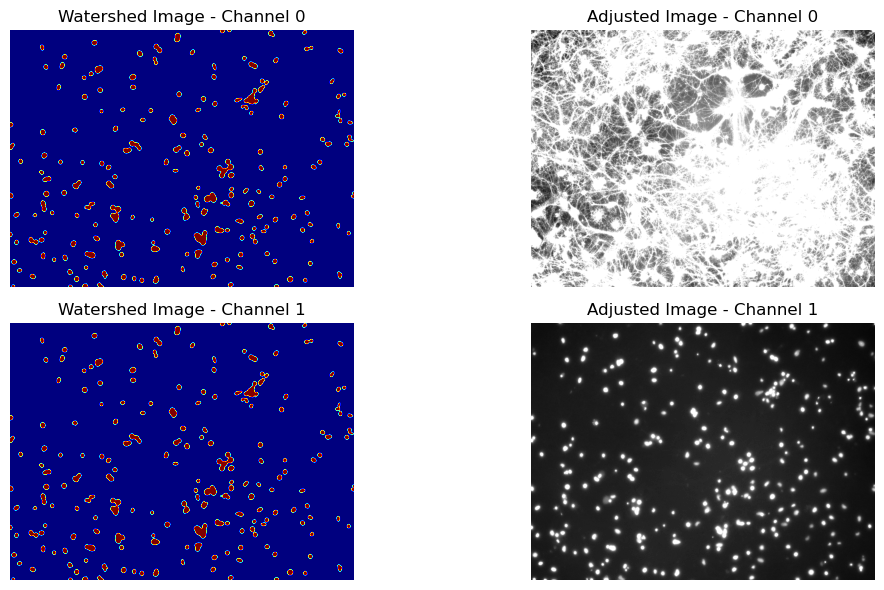

In [323]:
import matplotlib.pyplot as plt

# Assuming 'desired_filename' is the name of the image you want to display
desired_filename = 'G7 - 1.czi'

# Get the image from the 'watershed_images' dictionary using the filename
desired_image = watershed_images.get(desired_filename)

# Reshape the image to (M, N)
desired_image = desired_image[1, :, :]

# Get the corresponding adjusted images for both channels
adjusted_image_channel0 = adjusted_images[desired_filename][0]
adjusted_image_channel1 = adjusted_images[desired_filename][1]

# Create a 2x2 grid of subplots
fig, axs = plt.subplots(2, 2, figsize=(12, 6))

# Display the watershed image for channel 0
axs[0, 0].imshow(desired_image, cmap='jet')
axs[0, 0].set_title('Watershed Image - Channel 0')
axs[0, 0].axis('off')

# Display the adjusted image for channel 0
axs[0, 1].imshow(adjusted_image_channel0, cmap='gray')
axs[0, 1].set_title('Adjusted Image - Channel 0')
axs[0, 1].axis('off')

# Display the watershed image for channel 1
axs[1, 0].imshow(desired_image, cmap='jet')
axs[1, 0].set_title('Watershed Image - Channel 1')
axs[1, 0].axis('off')

# Display the adjusted image for channel 1
axs[1, 1].imshow(adjusted_image_channel1, cmap='gray')
axs[1, 1].set_title('Adjusted Image - Channel 1')
axs[1, 1].axis('off')

plt.tight_layout()
plt.show()


I looked through the images and saw that the vast majority of the time, the reason for the exceedingly high percentage was because of small flaws in the watershed function. This was especially true in wells with very high cell numbers: in those wells, it is a lot harder to get clean signal. Because of this, I did not alter any of the functions, and decided to give the wells with L/D ratios over 100 a value of 100%.

##### Adjusted Percentage Values

In [324]:
# Define a function to adjust the percentage values
def adjust_percentage(percentage):
    if percentage <= 100:
        return percentage
    else:
        return 100

# Create a new column 'Adjusted Percentage' based on the 'Percentage' column
df['Adjusted Percentage'] = df['Percentage'].apply(adjust_percentage)
df

,Well ID,Replicate,Contaminated,Number of ROIs Channel 0,Number of ROIs Channel 1,Ratio,Percentage,Adjusted Percentage
0,B10,1,C,2,131,0.015267,1.526718,1.526718
1,B10,2,C,6,147,0.040816,4.081633,4.081633
2,B10,3,C,2,182,0.010989,1.098901,1.098901
3,B11,1,C,19,192,0.098958,9.895833,9.895833
4,B11,2,C,13,193,0.067358,6.735751,6.735751
...,...,...,...,...,...,...,...,...
175,G8,2,C,54,326,0.165644,16.564417,16.564417
176,G8,3,C,26,162,0.160494,16.049383,16.049383
177,G9,1,N,1,306,0.003268,0.326797,0.326797
178,G9,2,N,1,269,0.003717,0.371747,0.371747


### Linking Corresponding Plate Map 

In [325]:
file_path_plate = "C:\\Users\\aless\\OneDrive - University of California, Davis\\experiments\\eAA076 - Rat Triculture Experiment with 6 proteins\\planning\\plate_map_1.xlsx"  # Replace with your file path
plate_map_df = pd.read_excel(file_path_plate)

In [326]:
import pandas as pd

# Load the plate map from the Excel file
plate_map_df = pd.read_excel(file_path_plate, header=None, skiprows=1)  # Skip the header row

# Create a mapping of Excel row and column indices to well IDs
def get_well_id(row_letter, col_number):
    return f"{row_letter}{col_number}"  # No need for zero-padding

# Create a list to store the parsed plate map data
plate_map_data = []

# Iterate over the DataFrame, adjusting the indices to match the plate map layout
for i, (index, row) in enumerate(plate_map_df.iterrows(), start=1):  # 'A' corresponds to index 1 in Excel
    row_letter = chr(64 + i)  # Convert to letter (A-H)
    for j, cell in enumerate(row, start=0):  # Column 1 corresponds to '1' in Excel
        if isinstance(cell, str):  # Check if the cell contains a string
            parts = cell.split(' | ')
            if len(parts) == 3:  # Ensure that there are three parts
                well_id = get_well_id(row_letter, j)
                # Check if we are in the sample area (rows C-G and columns 3-11)
                if row_letter >= 'B' and row_letter <= 'G' and 2 <= j <= 12:
                    plate_map_data.append({
                        'well_ID': well_id,
                        'DNA_name': parts[0],
                        'concentration': parts[1],
                        'LPS_conc': int(parts[2])
                    })

# Convert the list to a DataFrame
plate_map_df_new = pd.DataFrame(plate_map_data)

# Load your 'df' DataFrame from the CSV file
#df = pd.read_csv(file_path_df)  # Update with the path to your CSV

# Merge the plate map DataFrame with the 'df' DataFrame based on the Well IDs
merged_df = df.merge(plate_map_df_new, left_on='Well ID', right_on='well_ID', how='left')

# Drop the 'well_ID' column as it's redundant
merged_df.drop('well_ID', axis=1, inplace=True)

# Display the merged DataFrame
merged_df

,Well ID,Replicate,Contaminated,Number of ROIs Channel 0,Number of ROIs Channel 1,Ratio,Percentage,Adjusted Percentage,DNA_name,concentration,LPS_conc
0,B10,1,C,2,131,0.015267,1.526718,1.526718,Gal1,high,1
1,B10,2,C,6,147,0.040816,4.081633,4.081633,Gal1,high,1
2,B10,3,C,2,182,0.010989,1.098901,1.098901,Gal1,high,1
3,B11,1,C,19,192,0.098958,9.895833,9.895833,HGF,low,1
4,B11,2,C,13,193,0.067358,6.735751,6.735751,HGF,low,1
...,...,...,...,...,...,...,...,...,...,...,...
175,G8,2,C,54,326,0.165644,16.564417,16.564417,HGF,high,1
176,G8,3,C,26,162,0.160494,16.049383,16.049383,HGF,high,1
177,G9,1,N,1,306,0.003268,0.326797,0.326797,blank,low,0
178,G9,2,N,1,269,0.003717,0.371747,0.371747,blank,low,0


##### Troubleshooting dataframe

In [327]:
# Check for NaN values across the entire DataFrame
nan_exists = merged_df.isna().any().any()
print(f"Are there NaN values anywhere in the DataFrame? {nan_exists}")

# Check for NaN values in specific columns
nan_in_columns = merged_df[['DNA_name', 'concentration', 'LPS_conc']].isna().any()
print(f"Columns with NaN values: \n{nan_in_columns}")

nan_counts = merged_df.isna().sum()
print(f"Count of NaN values in each column: \n{nan_counts}")

Are there NaN values anywhere in the DataFrame? False
Columns with NaN values: 
DNA_name         False
concentration    False
LPS_conc         False
dtype: bool
Count of NaN values in each column: 
Well ID                     0
Replicate                   0
Contaminated                0
Number of ROIs Channel 0    0
Number of ROIs Channel 1    0
Ratio                       0
Percentage                  0
Adjusted Percentage         0
DNA_name                    0
concentration               0
LPS_conc                    0
dtype: int64


In [328]:
# Create a boolean Series indicating rows with NaN values
rows_with_nan = df.isna().any(axis=1)

# Filter the DataFrame to show only rows with NaN values
nan_rows = df[rows_with_nan]
nan_rows

,Well ID,Replicate,Contaminated,Number of ROIs Channel 0,Number of ROIs Channel 1,Ratio,Percentage,Adjusted Percentage


In [329]:
# Define the path where you want to save the CSV file
output_folder = "C:\\Users\\aless\\OneDrive - University of California, Davis\\experiments\\eAA076 - Rat Triculture Experiment with 6 proteins\\data\\Live Dead Assay"  # Replace with your actual folder path
output_filename = 'plate_1_data.csv'  
output_path = os.path.join(output_folder, output_filename)

# Make sure the output folder exists, if not, create it
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# Export the DataFrame to a CSV file
merged_df.to_csv(output_path, index=False)

print(f"DataFrame is saved successfully to {output_path}")


DataFrame is saved successfully to C:\Users\aless\OneDrive - University of California, Davis\experiments\eAA076 - Rat Triculture Experiment with 6 proteins\data\Live Dead Assay\plate_1_data.csv
